# Local comparison: MiniLM, BGE-small and every trained Ettin exit
Run this notebook in a **local Python kernel**, with CUDA if available (CPU is supported). No Colab runtime is required.
All code is inline. No backbone training or changes to your Drive experiment occur.

Manually download and extract your notebook 06 run folder. Both training checkpoints and a completed
export are supported; no Google authentication or download code is used.

Compare **all exported exit depths × trained dimensions** against full 384D MiniLM and BGE-small:
* The same pinned NanoNQ, NanoHotpotQA and NanoMSMARCO corpus/query/qrel sets as notebook 06.
* Same-exit retrieval and early queries against a full-depth Ettin document index.
* Untouched Twitter URL paraphrase test: ROC-AUC and average precision.
* Optional **fresh frozen-embedding classifiers** for GoEmotions and TweetTopic, to separate encoder quality
  from notebook 06's auxiliary-head problems. These are a new controlled probe protocol, not the old F1 scores.
* Actual prefix-only latency, active/stored parameter counts, numerical/padding checks and CSV/JSON plots.

Baselines are not Matryoshka-trained: do not truncate them to 128/256D and call that a fair baseline.
A common token cap does not imply identical text truncation across tokenizers. BGE uses its recommended query
instruction for retrieval only; no instruction for documents or symmetric paraphrase/classification tasks.
Sources: [MiniLM](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
[BGE](https://huggingface.co/BAAI/bge-small-en-v1.5).


In [5]:
# Install PyTorch into this kernel only if it is missing; preserve existing working installations.
import importlib.util
import subprocess
import sys
if importlib.util.find_spec("torch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch==2.10.0"])
print("Notebook Python:", sys.executable)
%pip install -q transformers==5.1.0 datasets==4.5.0 safetensors huggingface_hub scikit-learn==1.7.2 pandas matplotlib tqdm


Notebook Python: /home/coll/mondrianpolyarecom/.venv-embeddings/bin/python

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
!uv pip install torch

Using Python 3.12.12 environment at: /home/coll/mondrianpolyarecom/.venv-embeddings
Resolved 29 packages in 17ms                                         
Uninstalled 4 packages in 248ms
Installed 2 packages in 703ms                               
 - cuda-bindings==12.9.4
 ~ cuda-bindings==13.4.3
 - torch==2.10.0
 ~ torch==2.14.0


In [7]:
import os, json, hashlib, copy, time, gc, gzip
from pathlib import Path, PurePosixPath
from collections import defaultdict
from contextlib import nullcontext
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from transformers import AutoModel, AutoTokenizer, AutoConfig
from transformers.models.modernbert.modeling_modernbert import create_bidirectional_mask, create_bidirectional_sliding_window_mask
from huggingface_hub import hf_hub_download
from datasets import load_dataset
from safetensors.torch import load_file
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
os.environ['TOKENIZERS_PARALLELISM']='false'


## Local artifacts
The default uses the manually copied `social-encoder/` export in this repository.

Set `ARTIFACT_MODE='checkpoints'` and point `ARTIFACT_DIR` to the manually downloaded notebook 06 run folder.
Download **config.json**, **checkpoints/prefix/** and **checkpoints/exits/**, keeping their directory layout.
Keep every retained generation in those two stage folders, including each `state.pt` and `COMMITTED.json`.
The loader selects the best exit checkpoint recorded by the latest saved generation, then loads the exact
prefix checkpoint used to train those heads. It verifies checksums, run identity and the backbone tensor hash.
Only load your own training checkpoints: their PyTorch payload includes pickled optimizer/RNG state.

Alternatively set `ARTIFACT_MODE='export'` and point `ARTIFACT_DIR` to an extracted `social-encoder` export.
Public Hugging Face models, tokenizer files and benchmark datasets still download as needed. No Drive access
is performed by this notebook. Extract downloaded ZIPs first.


In [8]:
ARTIFACT_MODE = 'export'  # or 'checkpoints' for a notebook 06 run directory
# Works with a kernel launched from the repository root or notebook directory.
REPO_DIR = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'social-encoder' / 'encoder.json').is_file()), Path.cwd())
ARTIFACT_DIR = REPO_DIR / 'social-encoder'
RESULTS_BASE = Path.home() / 'encoder-benchmarks' / 'results'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
PRECISION = 'float32'  # 'bfloat16' is optional on supported CUDA; same policy for all encoders
MAX_LENGTH = 256
BATCH_SIZE = 32 if DEVICE=='cuda' else 8
CPU_THREADS = min(8, os.cpu_count() or 1)
RUN_PROBES = True
PROBE_TRAIN_CAP, PROBE_VALIDATION_CAP, PROBE_TEST_CAP = 4000, 512, 1000
SEED = 42
LATENCY_REPEATS = 10
BASELINES = {
 'MiniLM':dict(id='sentence-transformers/all-MiniLM-L6-v2',revision='1110a243fdf4706b3f48f1d95db1a4f5529b4d41',pooling='mean'),
 'BGE-small':dict(id='BAAI/bge-small-en-v1.5',revision='5c38ec7c405ec4b44b94cc5a9bb96e735b38267a',pooling='cls'),
}
BGE_QUERY_PREFIX = 'Represent this sentence for searching relevant passages: '
NANO=dict(id='sentence-transformers/NanoBEIR-en',revision='beb106fbcfaa599c508c667041bf8c85fd78736b')
TWITTER=dict(id='mteb/twitterurlcorpus-pairclassification',revision='ee5d15331196ec9f72e8393779b20098c10e29f6')
GO=dict(id='google-research-datasets/go_emotions',revision='add492243ff905527e67aeb8b80c082af02207c3')
TOPIC=dict(id='cardiffnlp/tweet_topic_single',revision='87b7a0d1c402dbb481db649569c556d9aa27ac05')
BENCHMARK_NAMES=['NanoNQ','NanoHotpotQA','NanoMSMARCO']
torch.set_num_threads(CPU_THREADS);torch.manual_seed(SEED);np.random.seed(SEED)
assert PRECISION in ('float32','bfloat16')
if PRECISION=='bfloat16':assert DEVICE=='cuda' and torch.cuda.is_bf16_supported()
def amp():return torch.autocast('cuda',dtype=torch.bfloat16) if PRECISION=='bfloat16' else nullcontext()
def sync():
    if DEVICE=='cuda':torch.cuda.synchronize()
def sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''):h.update(chunk)
    return h.hexdigest()
def digest(x):return hashlib.sha256(json.dumps(x,sort_keys=True).encode()).hexdigest()
def write_json(path,obj):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_suffix(path.suffix+'.tmp');temp.write_text(json.dumps(obj,indent=2));os.replace(temp,path)
def safe_relative(name):
    p=PurePosixPath(name)
    if p.is_absolute() or not p.parts or any(x in ('..','.') for x in p.parts) or '\\' in name:
        raise ValueError(f'Unsafe artifact path: {name}')
    return p
print('Device:',DEVICE,'precision:',PRECISION,'CPU threads:',CPU_THREADS)


Device: cuda precision: float32 CPU threads: 8


In [9]:
def read_generation(path, stage, contract_id):
    meta=json.loads((path/'COMMITTED.json').read_text())
    assert meta['contract']==contract_id, f'Wrong run: {path}'
    assert sha(path/'state.pt')==meta['sha256'], f'Incomplete/corrupt checkpoint: {path}'
    # These are the user's own notebook 06 checkpoints, including optimizer/RNG pickle state.
    state=torch.load(path/'state.pt',map_location='cpu',weights_only=False)
    assert state['contract']==contract_id and state['step']==meta['step']
    assert state['stage']==stage, f'Wrong stage: {path}'
    return state,meta

def select_generation(stage, contract_id, step=None):
    parent=ARTIFACT_DIR/'checkpoints'/stage
    candidates=sorted((p for p in parent.glob('*') if p.is_dir() and not p.name.startswith('.')
                       and (p/'COMMITTED.json').is_file()),reverse=True)
    if not candidates:raise FileNotFoundError(f'Copy the completed {parent} generations, with state.pt and COMMITTED.json.')
    if step is None:
        latest,meta=read_generation(candidates[0],stage,contract_id)
        step=latest['best_step']
        if latest['step']==step:return latest,meta
        del latest
    for path in candidates:
        if path.name.startswith(f'{step:08d}-'):
            state,meta=read_generation(path,stage,contract_id)
            assert state['step']==step
            return state,meta
    raise FileNotFoundError(f'Required {stage} step {step} missing from {parent}; copy all retained generations.')

prefix_state=None;exit_weights=None
if ARTIFACT_MODE=='checkpoints':
    contract=json.loads((ARTIFACT_DIR/'config.json').read_text());contract_id=digest(contract)
    exit_state,exit_meta=select_generation('exits',contract_id)
    assert exit_state['family']=='ettin-exits'
    SOURCE_MODEL_SPEC=exit_state['spec']
    assert SOURCE_MODEL_SPEC['kind']=='transformer' and SOURCE_MODEL_SPEC['independent_heads']
    selected_prefix=SOURCE_MODEL_SPEC['prefix_selected']['step']
    prefix_state,prefix_meta=select_generation('prefix',contract_id,selected_prefix)
    assert prefix_state['family']=='ettin' and prefix_state['data_id']==exit_state['data_id']
    exit_weights=exit_state['model']
    META=dict(depths=SOURCE_MODEL_SPEC['depths'],dimensions=contract['dimensions'],
              max_length=contract['config']['short_length'],exit_spec=SOURCE_MODEL_SPEC,
              selected=dict(prefix=selected_prefix,exits=exit_state['step']))
    artifact_identity=dict(mode=ARTIFACT_MODE,contract=contract_id,prefix=prefix_meta['sha256'],exits=exit_meta['sha256'])
    del exit_state
else:
    assert ARTIFACT_MODE=='export'
    manifest=json.loads((ARTIFACT_DIR/'COMMITTED.json').read_text())
    for name,expected in manifest['checksums'].items():
        safe_relative(name);assert sha(ARTIFACT_DIR/name)==expected,f'Corrupt or incomplete artifact: {name}'
    assert {'encoder.json','exits.safetensors','backbone/config.json'}<=manifest['checksums'].keys()
    META=json.loads((ARTIFACT_DIR/'encoder.json').read_text())
    artifact_identity=dict(mode=ARTIFACT_MODE,manifest_sha=sha(ARTIFACT_DIR/'COMMITTED.json'))
DEPTHS=META['depths'];DIMS=META['dimensions'];SOURCE_MODEL_SPEC=META['exit_spec']
assert MAX_LENGTH<=META['max_length'], 'Increase the cap only as a separate extrapolation experiment.'
IDENTITY=dict(artifact=artifact_identity,baselines=BASELINES,nano=NANO,twitter=TWITTER,
              go=GO,topic=TOPIC,length=MAX_LENGTH,precision=PRECISION,device=DEVICE,batch=BATCH_SIZE,
              cpu_threads=CPU_THREADS,seed=SEED,probes=RUN_PROBES,probe_caps=[PROBE_TRAIN_CAP,PROBE_VALIDATION_CAP,PROBE_TEST_CAP],
              bge_query_prefix=BGE_QUERY_PREFIX,torch_version=torch.__version__,
              hardware=torch.cuda.get_device_name() if DEVICE=='cuda' else 'cpu',implementation=2)
OUT=RESULTS_BASE/digest(IDENTITY)[:16];OUT.mkdir(parents=True,exist_ok=True)
write_json(OUT/'config.json',IDENTITY)
print('Verified local artifacts:',ARTIFACT_DIR,'Selected:',META['selected'],'Results:',OUT)


Verified local artifacts: /home/coll/mondrianpolyarecom/social-encoder Selected: {'backbone': {'step': 10000, 'score': 0.6841803691107712, 'completed_steps': 10000}, 'prefix': {'step': 3750, 'score': 0.6780785776731876, 'completed_steps': 5000}, 'exits': {'step': 9750, 'score': 0.6637920306328879, 'completed_steps': 10000}} Results: /home/coll/encoder-benchmarks/results/432fa34e2e42fe47


## Load the verified Ettin backbone and matching exit heads


In [10]:
if ARTIFACT_MODE=='checkpoints':
    spec=copy.deepcopy(prefix_state['spec']);typ=spec.pop('model_type')
    assert typ=='modernbert'
    backbone=AutoModel.from_config(AutoConfig.for_model(typ,**spec),attn_implementation='sdpa')
    weights={k.removeprefix('backbone.'):v for k,v in prefix_state['model'].items() if k.startswith('backbone.')}
    backbone.load_state_dict(weights,strict=True)
    h=hashlib.sha256()
    for k,v in backbone.state_dict().items():
        h.update(k.encode());h.update(v.detach().cpu().contiguous().view(torch.uint8).numpy().tobytes())
    assert h.hexdigest()==SOURCE_MODEL_SPEC['backbone_sha'], 'Exit heads and prefix backbone do not match.'
    tokenizer=AutoTokenizer.from_pretrained(contract['ettin']['id'],revision=contract['ettin']['revision'])
    del prefix_state,weights
    backbone.to(DEVICE).eval().requires_grad_(False)
else:
    backbone=AutoModel.from_pretrained(ARTIFACT_DIR/'backbone',attn_implementation='sdpa').to(DEVICE).eval().requires_grad_(False)
    tokenizer=AutoTokenizer.from_pretrained(ARTIFACT_DIR/'tokenizer')
NUM_LAYERS=backbone.config.num_hidden_layers
assert all(1<=d<NUM_LAYERS for d in DEPTHS)
def mean_pool(h,mask):
    weights=mask.unsqueeze(-1).float()
    return (h.float()*weights).sum(1)/weights.sum(1).clamp_min(1)


Loading weights: 100%|██████████| 62/62 [00:00<00:00, 881.47it/s, Materializing param=layers.9.mlp_norm.weight]       


In [11]:
def tokenize(texts):
    return tokenizer(texts,padding=True,truncation=True,max_length=MAX_LENGTH,return_tensors='pt').to(DEVICE)

@torch.no_grad()
def frozen_features(tokens,depths):
    backbone.eval()
    last=max(depths);assert 1<=last<=NUM_LAYERS
    h=backbone.embeddings(input_ids=tokens['input_ids'])
    positions=torch.arange(h.shape[1],device=h.device).unsqueeze(0)
    mask_args=dict(config=backbone.config,input_embeds=h,attention_mask=tokens['attention_mask'])
    masks={'full_attention':create_bidirectional_mask(**mask_args),
           'sliding_attention':create_bidirectional_sliding_window_mask(**mask_args)}
    rope={kind:backbone.rotary_emb(h,positions,kind) for kind in set(backbone.config.layer_types)}
    outputs={}
    for depth,layer in enumerate(backbone.layers[:last],1):
        h=layer(h,attention_mask=masks[layer.attention_type],position_embeddings=rope[layer.attention_type])
        if depth in depths:outputs[depth]=h.detach()
    return outputs,dict(masks=masks,rope=rope)

def native_pool(hidden,mask):
    return mean_pool(backbone.final_norm(hidden),mask)


class ExitHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm=copy.deepcopy(backbone.final_norm).requires_grad_(False)
        self.block=copy.deepcopy(backbone.layers[-1]).requires_grad_(True)
        self.block.gradient_checkpointing=False
    def forward(self,h,mask,context):
        typ=self.block.attention_type
        h=self.block(h,attention_mask=context['masks'][typ],position_embeddings=context['rope'][typ])
        return mean_pool(self.norm(h),mask)

class ExitBank(nn.Module):
    def __init__(self):
        super().__init__();self.family='ettin-exits';self.spec=copy.deepcopy(SOURCE_MODEL_SPEC)
        self.heads=nn.ModuleDict({str(d):ExitHead() for d in DEPTHS})
    def forward(self,depth,h,mask,context):return self.heads[str(depth)](h,mask,context)

def early_raw(tokens,depth,bank=None):
    features,context=frozen_features(tokens,[depth])
    if depth==NUM_LAYERS or bank is None:return native_pool(features[depth],tokens['attention_mask'])
    return bank(depth,features[depth],tokens['attention_mask'],context)


if ARTIFACT_MODE=='export':exit_weights=load_file(str(ARTIFACT_DIR/'exits.safetensors'))
bank=ExitBank().to(DEVICE);bank.load_state_dict(exit_weights,strict=True)
del exit_weights
bank.eval().requires_grad_(False)


ExitBank(
  (heads): ModuleDict(
    (1): ExitHead(
      (norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=False)
      (block): ModernBertEncoderLayer(
        (attn_norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=False)
        (attn): ModernBertAttention(
          (Wqkv): Linear(in_features=384, out_features=1152, bias=False)
          (Wo): Linear(in_features=384, out_features=384, bias=False)
          (out_drop): Identity()
        )
        (mlp_norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=False)
        (mlp): ModernBertMLP(
          (Wi): Linear(in_features=384, out_features=1152, bias=False)
          (act): GELUActivation()
          (drop): Dropout(p=0.0, inplace=False)
          (Wo): Linear(in_features=576, out_features=384, bias=False)
        )
      )
    )
    (2): ExitHead(
      (norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=False)
      (block): ModernBertEncoderLayer(
        (attn_norm

In [12]:
@torch.inference_mode()
def ettin_encode(texts,depths=None):
    depths=depths or DEPTHS+[NUM_LAYERS];result={d:[] for d in depths}
    for start in range(0,len(texts),BATCH_SIZE):
        tokens=tokenize(texts[start:start+BATCH_SIZE])
        with amp():
            features,ctx=frozen_features(tokens,depths)
            for d in depths:
                z=native_pool(features[d],tokens['attention_mask']) if d==NUM_LAYERS else bank(d,features[d],tokens['attention_mask'],ctx)
                assert torch.isfinite(z).all() and (z.float().norm(dim=-1)>1e-8).all()
                result[d].append(z.float().cpu())
    return {d:torch.cat(parts) for d,parts in result.items()}

baseline_models={}
def get_baseline(name):
    # Only one baseline on the accelerator at a time.
    for other,(model,_) in baseline_models.items():
        if other!=name:model.cpu()
    if name not in baseline_models:
        spec=BASELINES[name]
        tok=AutoTokenizer.from_pretrained(spec['id'],revision=spec['revision'])
        model=AutoModel.from_pretrained(spec['id'],revision=spec['revision'],attn_implementation='sdpa').eval().requires_grad_(False)
        baseline_models[name]=(model,tok)
    model,tok=baseline_models[name];model.to(DEVICE)
    return model,tok
@torch.inference_mode()
def baseline_encode(name,texts,retrieval_query=False):
    model,tok=get_baseline(name);parts=[]
    prefix=BGE_QUERY_PREFIX if name=='BGE-small' and retrieval_query else ''
    for start in range(0,len(texts),BATCH_SIZE):
        tokens=tok([prefix+t for t in texts[start:start+BATCH_SIZE]],padding=True,truncation=True,max_length=MAX_LENGTH,return_tensors='pt').to(DEVICE)
        with amp():
            h=model(**tokens).last_hidden_state
            z=h[:,0].float() if BASELINES[name]['pooling']=='cls' else mean_pool(h,tokens['attention_mask'])
        assert torch.isfinite(z).all() and (z.norm(dim=-1)>1e-8).all()
        parts.append(z.float().cpu())
    return torch.cat(parts)
def normalized(z,dim):return F.normalize(z[:,:dim].float(),dim=-1)
def cached_vectors(key,texts,encoder):
    identity=digest(dict(key=key,texts=texts));path=OUT/'vectors'/f'{identity}.npz'
    if path.exists():
        with np.load(path,allow_pickle=False) as data:return {k:torch.from_numpy(data[k].copy()) for k in data.files}
    values={str(k):v for k,v in encoder(texts).items()};path.parent.mkdir(exist_ok=True)
    temp=path.with_suffix('.tmp.npz');np.savez(temp,**{k:v.numpy() for k,v in values.items()});os.replace(temp,path)
    return values


## Numerical and actual early-exit checks (before expensive evaluation)


In [13]:
probe=['forgot my password lol','The library has books. '*20]
with torch.inference_mode(),amp():
    tokens=tokenize(probe);canonical=mean_pool(backbone(**tokens).last_hidden_state,tokens['attention_mask'])
    torch.testing.assert_close(canonical,early_raw(tokens,NUM_LAYERS,bank),atol=1e-5,rtol=1e-4)
counts=[0]*NUM_LAYERS
hooks=[layer.register_forward_hook(lambda m,a,o,i=i:counts.__setitem__(i,counts[i]+1)) for i,layer in enumerate(backbone.layers)]
try:
    with torch.inference_mode(),amp():early_raw(tokenize(probe),min(DEPTHS),bank)
finally:
    for hook in hooks:hook.remove()
assert counts==[int(i<min(DEPTHS)) for i in range(NUM_LAYERS)]
checks=[]
single=ettin_encode(probe[:1]);repeat=ettin_encode(probe[:1]);padded=ettin_encode(probe)
for d in single:
    for dim in DIMS:
        cosine=float(F.cosine_similarity(single[d][:,:dim],padded[d][:1,:dim]).item())
        assert cosine>.999 and torch.allclose(single[d],repeat[d],atol=1e-5,rtol=1e-4)
        checks.append(dict(model=f'Ettin-{d}',dim=dim,padding_cosine=cosine))
for name in BASELINES:
    a=baseline_encode(name,probe[:1]);b=baseline_encode(name,probe);r=baseline_encode(name,probe[:1])
    cosine=float(F.cosine_similarity(a,b[:1]).item());assert cosine>.999 and torch.allclose(a,r,atol=1e-5,rtol=1e-4)
    checks.append(dict(model=name,dim=a.shape[1],padding_cosine=cosine))
write_json(OUT/'numerical-checks.json',checks)
print('PASS: finite outputs, repeatability, padding, canonical parity, actual prefix-only execution')


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 756.19it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 690.85it/s, Materializing param=pooler.dense.weight]                               
BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


PASS: finite outputs, repeatability, padding, canonical parity, actual prefix-only execution


## Matched retrieval benchmarks
Every profile sees the same complete candidate corpus. Baselines use their own document embeddings;
`full_corpus` always means Ettin queries against Ettin full-depth documents, never incompatible model spaces.
Per-query scores and paired bootstrap differences are retained. NanoBEIR has only 50 queries per dataset;
small differences need caution. Existing training/pretraining overlap cannot be ruled out by this evaluation.


In [14]:
BENCHMARKS={}
for name in BENCHMARK_NAMES:
    parts={p:load_dataset('parquet',data_files={'train':f"hf://datasets/{NANO['id']}@{NANO['revision']}/{p}/{name}-*.parquet"},split='train') for p in ('queries','corpus','qrels')}
    queries={str(r['_id']):r['text'] for r in parts['queries'] if r['text'].strip()}
    docs={str(r['_id']):r['text'] for r in parts['corpus'] if r['text'].strip()};relevant=defaultdict(set)
    for r in parts['qrels']:
        ids=r['corpus-id'] if isinstance(r['corpus-id'],list) else [r['corpus-id']]
        relevant[str(r['query-id'])].update(map(str,ids))
    qids=[q for q in queries if relevant[q]]
    assert all(relevant[q]<=set(docs) for q in qids)
    BENCHMARKS[name]=dict(queries=queries,docs=docs,relevant=relevant,qids=qids)
def retrieval_per_query(q,p,qids,cids,relevant):
    scores=q@p.T;ranking=scores.argsort(dim=1,descending=True);rows=[]
    for i,qid in enumerate(qids):
        truth=relevant[qid];top=[cids[j] for j in ranking[i,:10].tolist()];hits=[int(x in truth) for x in top]
        dcg=sum(h/np.log2(j+2) for j,h in enumerate(hits));ideal=sum(1/np.log2(j+2) for j in range(min(10,len(truth))))
        rows.append(dict(query_id=qid,ndcg10=float(dcg/ideal),mrr10=next((1/(j+1) for j,h in enumerate(hits) if h),0.),
                         recall10=sum(hits)/len(truth),hit1=float(hits[0])))
    return rows
RETRIEVAL=[];PER_QUERY=[]
for dataset,b in BENCHMARKS.items():
    qids=b['qids'];cids=list(b['docs']);qt=[b['queries'][q] for q in qids];pt=list(b['docs'].values())
    def record(model,depth,dim,mode,q,p):
        rows=retrieval_per_query(normalized(q,dim),normalized(p,dim),qids,cids,b['relevant'])
        tags=dict(dataset=dataset,model=model,depth=depth,dim=dim,mode=mode)
        PER_QUERY.extend(dict(**tags,**r) for r in rows)
        RETRIEVAL.append(dict(**tags,**{k:float(np.mean([r[k] for r in rows])) for k in ('ndcg10','mrr10','recall10','hit1')}))
    for name in BASELINES:
        q=cached_vectors([name,dataset,'query'],qt,lambda t,n=name:{'full':baseline_encode(n,t,True)})['full']
        p=cached_vectors([name,dataset,'document'],pt,lambda t,n=name:{'full':baseline_encode(n,t)})['full']
        record(name,0,q.shape[1],'native',q,p)
    q=cached_vectors(['ettin',dataset,'query'],qt,ettin_encode);p=cached_vectors(['ettin',dataset,'document'],pt,ettin_encode)
    for depth in DEPTHS+[NUM_LAYERS]:
        for dim in DIMS:
            for mode,pdepth in [('same_exit',depth),('full_corpus',NUM_LAYERS)]:
                record('Ettin',depth,dim,mode,q[str(depth)],p[str(pdepth)])
    write_json(OUT/'retrieval.json',RETRIEVAL);write_json(OUT/'retrieval-per-query.json',PER_QUERY)
    print(dataset,'complete')
retrieval_df=pd.DataFrame(RETRIEVAL);retrieval_df.to_csv(OUT/'retrieval.csv',index=False)
display(retrieval_df)
# Paired bootstrap: same resampled queries for each comparison, not independent CIs.
DIFFERENCES=[];pq=pd.DataFrame(PER_QUERY)
for dataset in BENCHMARKS:
    frame=pq[pq.dataset==dataset]
    for baseline in BASELINES:
        ref=frame[frame.model==baseline].set_index('query_id').ndcg10
        for (depth,dim,mode),group in frame[frame.model=='Ettin'].groupby(['depth','dim','mode']):
            delta=group.set_index('query_id').ndcg10.reindex(ref.index).to_numpy()-ref.to_numpy()
            rng=np.random.default_rng(SEED);samples=delta[rng.integers(len(delta),size=(2000,len(delta)))].mean(1)
            DIFFERENCES.append(dict(dataset=dataset,baseline=baseline,depth=int(depth),dim=int(dim),mode=mode,
                delta_ndcg10=float(delta.mean()),ci_low=float(np.quantile(samples,.025)),ci_high=float(np.quantile(samples,.975))))
pd.DataFrame(DIFFERENCES).to_csv(OUT/'paired-differences.csv',index=False)


Generating train split: 50 examples [00:00, 4072.38 examples/s]
Generating train split: 5035 examples [00:00, 300189.35 examples/s]
Generating train split: 57 examples [00:00, 31477.99 examples/s]
Generating train split: 50 examples [00:00, 9305.79 examples/s]
Generating train split: 5090 examples [00:00, 602602.67 examples/s]
Generating train split: 100 examples [00:00, 65495.07 examples/s]
Generating train split: 50 examples [00:00, 34987.52 examples/s]
Generating train split: 5043 examples [00:00, 807755.10 examples/s]
Generating train split: 50 examples [00:00, 34357.01 examples/s]


NanoNQ complete
NanoHotpotQA complete
NanoMSMARCO complete


,dataset,model,depth,dim,mode,ndcg10,mrr10,recall10,hit1
0,NanoNQ,MiniLM,0,384,native,0.590387,0.545635,0.75,0.44
1,NanoNQ,BGE-small,0,384,native,0.594277,0.555603,0.76,0.44
2,NanoNQ,Ettin,1,128,same_exit,0.327570,0.269381,0.53,0.16
3,NanoNQ,Ettin,1,128,full_corpus,0.390803,0.363690,0.52,0.28
4,NanoNQ,Ettin,1,256,same_exit,0.346256,0.290937,0.55,0.20
...,...,...,...,...,...,...,...,...,...
181,NanoMSMARCO,Ettin,10,128,full_corpus,0.448155,0.379714,0.66,0.22
182,NanoMSMARCO,Ettin,10,256,same_exit,0.481966,0.413103,0.70,0.28
183,NanoMSMARCO,Ettin,10,256,full_corpus,0.481966,0.413103,0.70,0.28
184,NanoMSMARCO,Ettin,10,384,same_exit,0.480568,0.394056,0.76,0.24


## Untouched Twitter URL paraphrase evaluation (no retrieval instructions)


In [15]:
path=hf_hub_download(TWITTER['id'],'test.json.gz',revision=TWITTER['revision'],repo_type='dataset')
tweets=[]
with gzip.open(path,'rt') as f:
    for line in f:
        row=json.loads(line);tweets.extend(zip(row['sent1'],row['sent2'],row['labels']))
a,b,y=map(list,zip(*tweets));texts=a+b;n=len(a)
SOCIAL=[]
def score_twitter(model,depth,dim,z):
    z=normalized(z,dim);scores=(z[:n]*z[n:]).sum(-1).numpy()
    SOCIAL.append(dict(model=model,depth=depth,dim=dim,n=n,auc=float(roc_auc_score(y,scores)),average_precision=float(average_precision_score(y,scores))))
for name in BASELINES:
    z=cached_vectors([name,'twitter'],texts,lambda t,n=name:{'full':baseline_encode(n,t)})['full']
    score_twitter(name,0,z.shape[1],z)
vectors=cached_vectors(['ettin','twitter'],texts,ettin_encode)
for depth,z in vectors.items():
    for dim in DIMS:score_twitter('Ettin',int(depth),dim,z)
social_df=pd.DataFrame(SOCIAL);social_df.to_csv(OUT/'twitter.csv',index=False);write_json(OUT/'twitter.json',SOCIAL)
display(social_df)
del vectors;gc.collect()


,model,depth,dim,n,auc,average_precision
0,MiniLM,0,384,51534,0.938080,0.847017
1,BGE-small,0,384,51534,0.938289,0.848388
2,Ettin,1,128,51534,0.880112,0.749814
3,Ettin,1,256,51534,0.878630,0.746628
4,Ettin,1,384,51534,0.880114,0.746530
5,Ettin,2,128,51534,0.878208,0.746231
6,Ettin,2,256,51534,0.875682,0.742715
7,Ettin,2,384,51534,0.876617,0.742614
8,Ettin,3,128,51534,0.873673,0.740035
9,Ettin,3,256,51534,0.871589,0.736815


93

## Optional matched frozen-embedding classification probes
All encoders get freshly fitted logistic classifiers, the same deterministic samples, and the same regularization.
Full 384D only here: isolates depth/encoder quality without multiplying the CPU classifier work by three.
GoEmotions uses balanced one-vs-rest classifiers; one global threshold is selected **only on validation micro-F1**.
Report both calibrated and fixed-0.5 test scores, per-label AP and predicted-label counts.
TweetTopic uses the official 2020 train/validation and 2021 test files with a balanced classifier.

These supervised probes can reuse texts seen in Ettin's training; labels on the official held-out splits must not
have been used for training. They measure the resulting representations, not zero-shot classification. Different
upstream pretraining exposure between models remains a limitation. Probe samples and thresholds are saved.


In [16]:
PROBE_RESULTS=[]
if RUN_PROBES:
    def tid(s):return hashlib.sha256(' '.join(s.split()).casefold().encode()).hexdigest()
    def sample(ds,cap):
        order=np.random.default_rng(SEED).permutation(len(ds));return [dict(ds[int(i)]) for i in order[:cap]]
    probe_data={}
    for task,spec in [('emotion',GO),('topic',TOPIC)]:
        parts={}
        for split,cap in zip(('train','validation','test'),(PROBE_TRAIN_CAP,PROBE_VALIDATION_CAP,PROBE_TEST_CAP)):
            if task=='emotion':ds=load_dataset(spec['id'],'simplified',revision=spec['revision'],split=split)
            else:
                stem={'train':'train_2020','validation':'validation_2020','test':'test_2021'}[split]
                path=hf_hub_download(spec['id'],f'dataset/split_temporal/{stem}.single.json',revision=spec['revision'],repo_type='dataset')
                ds=[json.loads(l) for l in Path(path).read_text().splitlines() if l.strip()]
            parts[split]=sample(ds,cap)
        # Reserve test/validation before training; identical text stays in one split.
        seen=set()
        for split in ('test','validation','train'):
            clean=[]
            for r in parts[split]:
                key=tid(r['text'])
                if key not in seen:clean.append(r);seen.add(key)
            parts[split]=clean
        probe_data[task]=parts
    write_json(OUT/'probe-sample-ids.json',{t:{s:[tid(r['text']) for r in rows] for s,rows in parts.items()} for t,parts in probe_data.items()})
    for task,parts in probe_data.items():
        texts=[r['text'] for split in ('train','validation','test') for r in parts[split]]
        nt,nv=len(parts['train']),len(parts['validation'])
        def labels(rows):
            if task=='topic':return np.array([r['label'] for r in rows])
            y=np.zeros((len(rows),28),dtype=int)
            for i,r in enumerate(rows):y[i,r['labels']]=1
            return y
        yt,yv,ys=[labels(parts[s]) for s in ('train','validation','test')]
        profiles={}
        for name in BASELINES:
            profiles[(name,0)]=cached_vectors([name,'probe',task],texts,lambda t,n=name:{'full':baseline_encode(n,t)})['full']
        for d,z in cached_vectors(['ettin','probe',task],texts,ettin_encode).items():profiles[('Ettin',int(d))]=z
        for (name,depth),raw in tqdm(profiles.items(),desc=f'{task} probes'):
            x=normalized(raw,384).numpy();train,val,test=x[:nt],x[nt:nt+nv],x[nt+nv:]
            classifier=LogisticRegression(C=10.,class_weight='balanced',max_iter=1000,solver='liblinear',random_state=SEED)
            if task=='emotion':
                classifier=OneVsRestClassifier(classifier,n_jobs=1).fit(train,yt)
                vp=classifier.predict_proba(val);tp=classifier.predict_proba(test)
                grid=np.linspace(.05,.95,37)
                threshold=float(max(grid,key=lambda th:f1_score(yv,vp>=th,average='micro',zero_division=0)))
                pred=tp>=threshold
                aps=[float(average_precision_score(ys[:,i],tp[:,i])) if ys[:,i].sum()>0 else None for i in range(28)]
                metrics=dict(micro_f1=float(f1_score(ys,pred,average='micro',zero_division=0)),macro_f1=float(f1_score(ys,pred,average='macro',zero_division=0)),
                    fixed_05_micro_f1=float(f1_score(ys,tp>=.5,average='micro',zero_division=0)),threshold=threshold,
                    predicted_labels_per_example=float(pred.sum(1).mean()),true_labels_per_example=float(ys.sum(1).mean()),per_label_ap=aps)
            else:
                classifier=OneVsRestClassifier(classifier,n_jobs=1).fit(train,yt);pred=classifier.predict(test)
                metrics=dict(macro_f1=float(f1_score(ys,pred,labels=list(range(6)),average='macro',zero_division=0)),accuracy=float(accuracy_score(ys,pred)))
            PROBE_RESULTS.append(dict(task=task,model=name,depth=depth,dim=384,n_train=nt,n_validation=nv,n_test=len(test),**metrics))
            write_json(OUT/'probes.json',PROBE_RESULTS)
    pd.DataFrame(PROBE_RESULTS).to_csv(OUT/'probes.csv',index=False)
    display(pd.DataFrame(PROBE_RESULTS).drop(columns=['per_label_ap'],errors='ignore'))


topic probes: 100%|██████████| 12/12 [00:05<00:00,  2.19it/s]


,task,model,depth,dim,n_train,n_validation,n_test,micro_f1,macro_f1,fixed_05_micro_f1,threshold,predicted_labels_per_example,true_labels_per_example,accuracy
0,emotion,MiniLM,0,384,3991,511,1000,0.335462,0.296898,0.328373,0.575,2.450,1.151,NaN
1,emotion,BGE-small,0,384,3991,511,1000,0.396018,0.390893,0.380665,0.700,1.662,1.151,NaN
2,emotion,Ettin,1,384,3991,511,1000,0.297652,0.276043,0.289964,0.775,1.362,1.151,NaN
3,emotion,Ettin,2,384,3991,511,1000,0.291595,0.254067,0.273832,0.725,1.764,1.151,NaN
4,emotion,Ettin,3,384,3991,511,1000,0.300654,0.257907,0.278742,0.725,1.756,1.151,NaN
5,emotion,Ettin,4,384,3991,511,1000,0.296787,0.246881,0.275694,0.625,2.771,1.151,NaN
6,emotion,Ettin,5,384,3991,511,1000,0.302992,0.258190,0.278742,0.700,2.024,1.151,NaN
7,emotion,Ettin,6,384,3991,511,1000,0.312062,0.289677,0.283861,0.775,1.419,1.151,NaN
8,emotion,Ettin,7,384,3991,511,1000,0.322556,0.274689,0.286915,0.775,1.509,1.151,NaN
9,emotion,Ettin,8,384,3991,511,1000,0.311698,0.260398,0.291436,0.750,1.653,1.151,NaN


## Measured prefix-only latency and parameter costs
Encoding latency includes tokenization, device transfer, pooling and transfer of output to CPU; excludes loading,
network, disk cache and nearest-neighbor search. Each Ettin timing runs ONLY the selected prefix and one exit.
Use the same real document sample and batch size for all models; report batch-1 and batch-throughput separately.
All dimensions share encoder cost; slicing to 128D saves index work/storage, not backbone computation.


In [17]:
def nparams(module):return sum(p.numel() for p in module.parameters())
TIMINGS=[]
texts=list(next(iter(BENCHMARKS.values()))['docs'].values())[:max(32,BATCH_SIZE)]
original_batch=BATCH_SIZE
for batch in (1,original_batch):
    BATCH_SIZE=batch;sample_text=texts[:batch]
    encoders=[(name,0,lambda t,n=name:baseline_encode(n,t)) for name in BASELINES]
    encoders += [('Ettin',d,lambda t,depth=d:ettin_encode(t,[depth])) for d in DEPTHS+[NUM_LAYERS]]
    for name,depth,encode in encoders:
        for _ in range(3):encode(sample_text)
        sync();elapsed=[]
        for _ in range(LATENCY_REPEATS):
            sync();start=time.perf_counter();encode(sample_text);sync();elapsed.append(time.perf_counter()-start)
        if name=='Ettin':
            stored=nparams(backbone)+nparams(bank)
            active=nparams(backbone.embeddings)+sum(nparams(layer) for layer in backbone.layers[:depth])
            active+=nparams(backbone.final_norm) if depth==NUM_LAYERS else nparams(bank.heads[str(depth)])
        else:stored=active=nparams(get_baseline(name)[0])
        TIMINGS.append(dict(model=name,depth=depth,batch=batch,median_ms=float(np.median(elapsed)*1000),
            p95_ms=float(np.percentile(elapsed,95)*1000),texts_per_second=len(sample_text)/float(np.median(elapsed)),
            stored_parameters=stored,active_parameters=active))
BATCH_SIZE=original_batch
pd.DataFrame(TIMINGS).to_csv(OUT/'latency.csv',index=False);write_json(OUT/'latency.json',TIMINGS)
display(pd.DataFrame(TIMINGS))


,model,depth,batch,median_ms,p95_ms,texts_per_second,stored_parameters,active_parameters
0,MiniLM,0,1,5.314786,7.335789,188.154347,22713216,22713216
1,BGE-small,0,1,6.859036,9.595939,145.793092,33360000,33360000
2,Ettin,1,1,3.244958,5.369932,308.170442,43173888,21849984
3,Ettin,2,1,3.315616,4.524918,301.603081,43173888,23104128
4,Ettin,3,1,3.775318,4.541151,264.878351,43173888,24358272
5,Ettin,4,1,4.109381,5.825896,243.345676,43173888,25612416
6,Ettin,5,1,4.431684,4.788392,225.647879,43173888,26866560
7,Ettin,6,1,5.050425,5.250296,198.003140,43173888,28120704
8,Ettin,7,1,5.382733,5.783546,185.779215,43173888,29374848
9,Ettin,8,1,5.577080,5.818748,179.305284,43173888,30628992


## Comparison plots and saved report


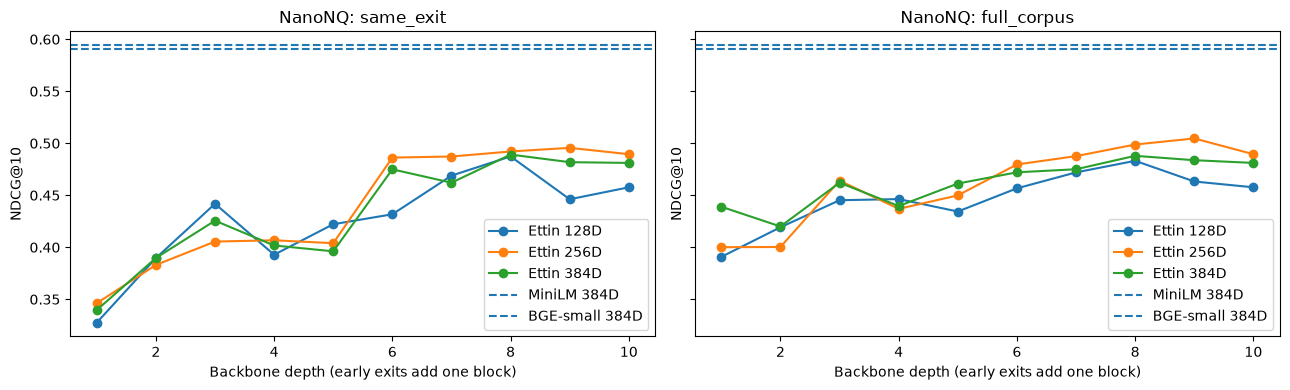

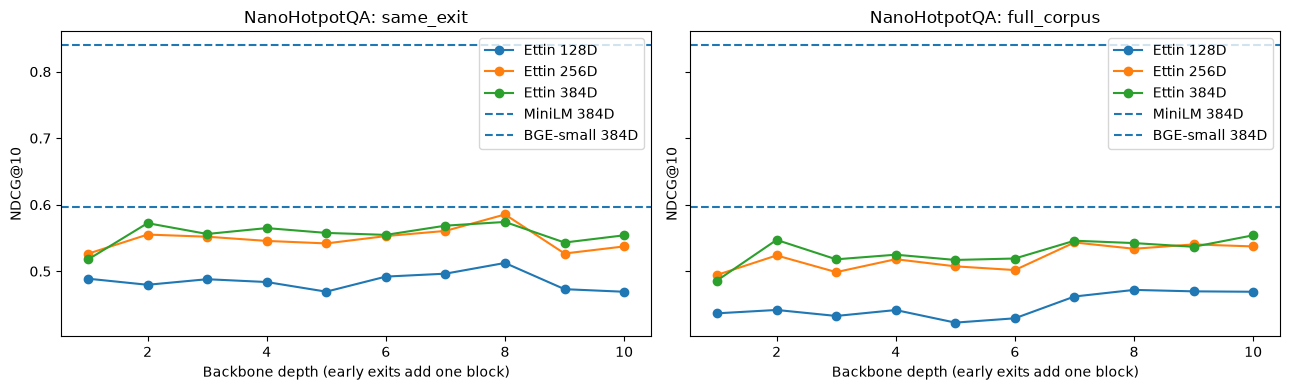

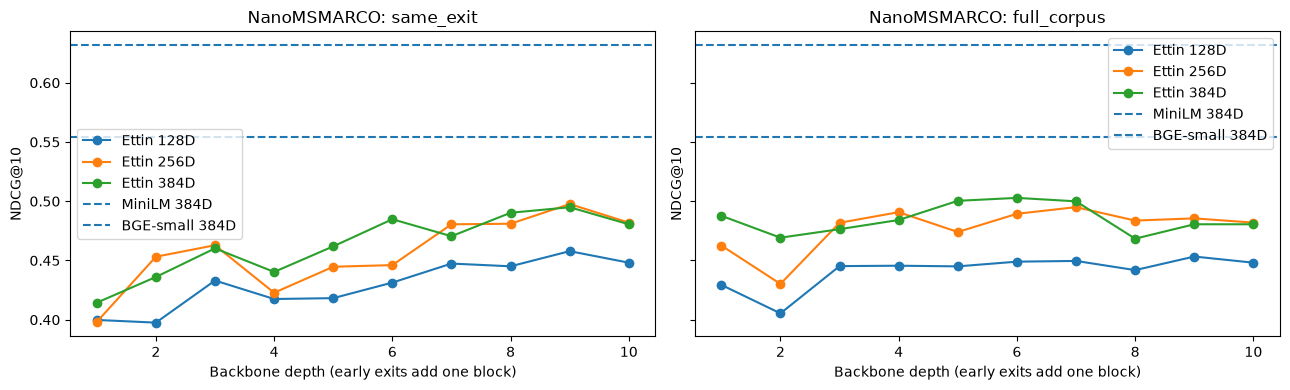

Results saved to: /home/coll/encoder-benchmarks/results/432fa34e2e42fe47
Read paired-differences.csv for uncertainty, latency.csv for actual speed, and probes.json for classifier diagnostics.


In [18]:
for dataset in BENCHMARKS:
    fig,axes=plt.subplots(1,2,figsize=(13,4),sharey=True)
    for ax,mode in zip(axes,['same_exit','full_corpus']):
        frame=retrieval_df[retrieval_df.dataset==dataset]
        for dim in DIMS:
            r=frame[(frame.model=='Ettin')&(frame['mode']==mode)&(frame.dim==dim)].sort_values('depth')
            ax.plot(r.depth,r.ndcg10,marker='o',label=f'Ettin {dim}D')
        for name in BASELINES:
            score=float(frame[frame.model==name].ndcg10.iloc[0]);ax.axhline(score,ls='--',label=f'{name} 384D')
        ax.set(title=f'{dataset}: {mode}',xlabel='Backbone depth (early exits add one block)',ylabel='NDCG@10');ax.legend()
    fig.tight_layout();fig.savefig(OUT/f'{dataset}.png',dpi=150);plt.show()
write_json(OUT/'COMPLETE.json',dict(identity=IDENTITY,retrieval_profiles=len(RETRIEVAL),twitter_profiles=len(SOCIAL),
    probe_profiles=len(PROBE_RESULTS),note='Completed local evaluation; no Drive writes or training of encoder weights.'))
print('Results saved to:',OUT)
print('Read paired-differences.csv for uncertainty, latency.csv for actual speed, and probes.json for classifier diagnostics.')
